<a href="https://colab.research.google.com/github/aurelianmoge/CE-4110-UVa-personal-work/blob/main/Homework4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 4

**Problem 1: Seasonal workers**

Question a)

We define x that counts workers without a high school degree, while y counts those with a degree.
The objective, z, counts expected monthly participants.

We set, thus, the problem:

max z = 5x + 8y,

st:
1) $x+y \leq 6$ (limits headcount)
2) $15x + 27y \leq 135$ (limits the hourly payroll),

where x and y are integer.

Question b)

In [8]:
from scipy.optimize import linprog
r = linprog([-5, -8],
            A_ub=[[1, 1], [15, 27]],
            b_ub=[6, 135],
            method="highs")
print(r.x, -r.fun)  # [2.25, 3.75], 41.25

[2.25 3.75] 41.25


Removing integrality gives (x=2.25,\ y=3.75), with (z=41.25).
This is an upper bound on the integer solution.

Question c)

Because $z=5x+8y$ is an integer, the upper bound $40.556$ implies $z\le40$. All terminal branches are therefore infeasible or bounded at 40 or less. The feasible plan $(x,y)=(0,5)$ achieves 40, proving optimality.

Thus, we should hire five workers with a high school degree and none without. Payroll is 135 dollars/hour, and participation is 40 Junior Rangers/month, which is 1.25 below the LP relaxation.

Compared to the solution found in b), it might be counterintuitive: the need for an integer values leads to hire no student without a high school degree, while they would have represented at least a third if we had allowed for non-integer values.

## Problem 2: Simple unit commitment

Adapt the unit commitment code from class to model PHS as a battery. The model for that is the following:


$$
\begin{align}
\min \sum_{g \notin PHS, t \in T} VarCost_g \times GEN_{g,t} + \sum_{g \in G_{thermal}, t \in T} StartUpCost_g \times START_{g,t} + \\
\sum_{t \in T} VarCost_{PHS} \times (DISCHARGE_t + CHARGE_t) \\
\end{align}
$$
$$
\begin{align}
\text{s.t.} & \\
 & \sum_{g \notin PHS} GEN_{g,t} + DISCHARGE_t - CHARGE_t = Demand_t \quad \forall \quad t \in T\\
 & GEN_{g,t} \leq Pmax_{g,t} & \forall \quad g \notin G_{thermal} , t \in T \\
 & GEN_{g,t} \geq Pmin_{g,t} & \forall \quad g \notin G_{thermal} , t \in T \\
 & GEN_{g,t} \leq Pmax_{g,t} \times COMMIT_{g,t} & \forall \quad g \in G_{thermal} , t \in T \\
 & GEN_{g,t} \geq Pmin_{g,t} \times COMMIT_{g,t} & \forall \quad g \in G_{thermal} , t \in T \\
 & COMMIT_{g,t} \geq \sum_{t'≥t-MinUp_g}^{t} START_{g,t} & \forall \quad g \in G_{thermal} , t \in T \\
 & 1-COMMIT_{g,t} \geq \sum_{t'≥t-MinDown_g}^{t} SHUT_{g,t} &\forall \quad g \in G_{thermal} , t \in T \\
  & COMMIT_{g,t+1} - COMMIT_{g,t} = \quad START_{g,t+1} - SHUT_{g,t+1} &\forall \quad G_{thermal} \in G , t \in (1,...,T-1)\\
 &SOC_{t+1} = SOC_t + \big(CHARGE_{t+1} * battery\_eff - \frac{DISCHARGE_{t+1}}{battery\_eff}\big)  \quad &\forall t \in (1, ..., T-1)\\  
 &CHARGE_t \leq power\_cap \quad &\forall t \in T\\  
 &DISCHARGE_t \leq power\_cap \quad &\forall t \in T\\
 &SOC_t \leq energy\_cap \quad &\forall t \in T\\
 &SOC[0] = SOC[T] = 0.5 \times energy\_cap
\end{align}
$$


The **decision variables** in the above problem:

- $GEN_{g}$, generation (in MW) produced by each generator, $g$
- $START_{g,t}$, startup decision (binary) of thermal generator $g$ at time $t$
- $SHUT_{g,t}$, shutdown decision (binary) of thermal generator $g$ at time $t$
- $COMMIT_{g,t}$, commitment status (binary) of generator $g$ at time $t$
- $CHARGE_t$: How much DC power to charge to PHS (i.e. how much water to pump up water to upper reservoir); continuous
- $DISCHARGE_t$: How much DC power to discharge from PHS (i.e. how much water to release down to lower reservoir through turbines); continuous
- $SOC_t$: "Storage State of Charge" representing how much energy is stored in the battery (i.e., upper reservoir storage); continuous

The **parameters** are:

- $Pmin_g$, the minimum operating bounds for generator $g$ (based on engineering or natural resource constraints)
- $Pmax_g$, the maximum operating bounds for generator $g$ (based on engineering or natural resource constraints)
- $Demand$, the demand (in MW)
- $VarCost_g = VarOM_g + HeatRate_g \times FuelCost_g$, the variable cost of generator $g$
- $StartUpCost_g$, the startup cost of generator $g$
- $MinUp_g$, the minimum up time of generator $g$, or the minimum time after start-up before a unit can shut down
- $MinDown_g$, the minimum down time of generator $g$, or the minimum time after shut-down before a unit can start again
- $battery\_eff=0.84$: Fraction of the stored energy that can be converted to power.
- $power\_cap$: maximum power capacity of battery in MW, given in `existing_cap_mw` column of `gen_df` for `hydroelectric_pumped_storage`.
- $energy\_cap = 4 \times Pmax$: maximum energy in MWh that can be stored in the battery (i.e. upper reservoir)

$\color{red}{\text{Install gurobipy and load data on generators. The code below is complete.}}$

In [1]:
!pip install gurobipy
!pip install gurobipy_pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.9/14.9 MB 36.9 MB/s eta 0:00:00


In [2]:
import gurobipy as gp
from gurobipy import GRB
import gurobipy_pandas as gppd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# allow access to google drive
drive.mount('/content/drive')

datadir = "drive/MyDrive/CE-6250/UCED_data/"
gen_info = pd.read_csv(datadir + "Generators_data.csv")
fuels = pd.read_csv(datadir + "Fuels_data.csv")
loads = pd.read_csv(datadir + "Demand.csv")
gen_variable = pd.read_csv(datadir + "Generators_capacity_factors.csv")

# Keep columns relevant to our UCED model
gen_info = gen_info.iloc[:,0:26] # first 26 columns
gen_df = gen_info.join(fuels.set_index("Fuel"), on="Fuel")
gen_df.rename(columns={"Cost_per_MMBtu": "Fuel_cost"},inplace=True)
gen_df["Fuel_cost"].fillna(0) # replace NAs for fuel cost with 0

# create "is_variable" column to indicate if this is a variable generation source (e.g. wind, solar):
gen_df["Is_variable"] = False
indices = [i for i in gen_df.index if gen_df["Resource"][i] in ["onshore_wind_turbine","small_hydroelectric","solar_photovoltaic"]]
gen_df["Is_variable"].iloc[indices] = True

# create full name of generator (including geographic location and cluster number)
#  for use with variable generation dataframe
gen_df["Generator"] = gen_df["region"] + "_" + gen_df["Resource"] + "_" + gen_df["cluster"].astype("str") + ".0"

# remove generators with no capacity (e.g. new build options that we'd use if this was capacity expansion problem)
gen_df = gen_df[gen_df["Existing_Cap_MW"] > 0]

# set generator to index
gen_df.set_index("Generator",inplace=True)

Mounted at /content/drive


/tmp/ipykernel_2427/814597938.py:27: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  gen_df["Is_variable"].iloc[indices] = True
/tmp/ipykernel_2427/814597938.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from

$\color{red}{\text{Extract the necessary PHS data from gen_df and then drop it from gen_df. The code below is complete.}}$

In [3]:
# create dataframe with just hydroelectric_pumped_storage
hydro_psh = gen_df.iloc[np.where(gen_df["Resource"]
                                 =="hydroelectric_pumped_storage")[0],:]

# specify parameters to model PHS as a battery
psh_power_cap = float(gen_df["Existing_Cap_MW"].
                      iloc[np.where(
                          gen_df["Resource"]=="hydroelectric_pumped_storage")])
energy_cap = 4 * psh_power_cap
battery_eff = 0.84

# remove psh from generators dataframe
gen_df.drop(index=gen_df.index
 [np.where(gen_df["Resource"]=="hydroelectric_pumped_storage")[0]],
            inplace=True)

/tmp/ipykernel_2427/2048560286.py:5: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  psh_power_cap = float(gen_df["Existing_Cap_MW"].iloc[np.where(gen_df["Resource"]=="hydroelectric_pumped_storage")])


$\color{red}{\text{Create data frames for 1) all generators except PSH (all_gen_df), 2) all thermal generators (thermal_gen_df), and 3) Hydro PSF (hydro_psh_df).}}$  
$\color{red}{\text{The code below is complete.}}$

In [4]:
# 1. Convert from GMT to GMT-8
gen_variable["Hour"] = np.mod(gen_variable["Hour"]-9, 8760)
gen_variable = gen_variable.sort_values(by="Hour")
loads["Hour"] = np.mod(loads["Hour"]-9, 8760)
loads = loads.sort_values(by="Hour")
loads.set_index("Hour",inplace=True)
gen_variable.set_index("Hour",inplace=True)

### create multi-indexed dataframe for each decision variable index
list_of_indices = [
    list(gen_df.index), # generators
    list(gen_variable.index) # hours
]

multi_idx = pd.MultiIndex.from_product(list_of_indices,
                                       names=["Generator", "Hour"])

# create multi-index data frames with different sets of generators
all_gen_df = pd.DataFrame(index = multi_idx)

thermal_generators = gen_df.index[np.where(gen_df["Up_time"] > 0)[0]]
nonthermal_generators = gen_df.index[np.where(gen_df["Up_time"] == 0)[0]]
thermal_gen_df = all_gen_df.loc[thermal_generators.tolist()]

hydro_psh_indices = [["hydroelectric_pumped_storage"],
                     list(gen_variable.index)]
hydro_multi_idx = pd.MultiIndex.from_product(hydro_psh_indices,
                                             names=["Generator", "Hour"])
hydro_psh_df = pd.DataFrame(index=hydro_multi_idx)

$\color{red}{\text{Extract data for a spring day (hours 2400-2423) and increase the solar capacity. The code below is complete.}}$

In [5]:
# A spring day
n=100
T_period = np.arange(n*24,(n+1)*24)

# High solar case: 3,500 MW
gen_df_sens = gen_df.copy()
gen_df_sens["Existing_Cap_MW"][np.where(gen_df_sens["Resource"] == "solar_photovoltaic")[0]]= 3500

# subset only hours in T_period from all_gen_df, thermal_gen_df, nonthermal_gen_df and hydro_psh
idx = pd.IndexSlice
all_gen_df_springday = all_gen_df.loc[idx[:,T_period],:]
thermal_gen_df_springday = thermal_gen_df.loc[idx[:,T_period],:]
hydro_psh_df = hydro_psh_df.loc[idx[:,T_period],:]
loads_springday = loads["Demand"].iloc[T_period]

/tmp/ipykernel_2427/3843741305.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  gen_df_sens["Existing_Cap_MW"][np.where(gen_df_sens["Resource"] == "solar_photovoltaic")[0]]= 3500
/tmp/ipykernel_2427/3843741305.py:7: SettingWithCopyWarning

$\color{red}{\text{Create the model, set the MIPGap and create indices for sets of variables. The code below only needs to be edited to include your license codes.}}$

In [7]:
# Note we reduce the MIP gap tolerance threshold here to increase tractability
# Here we set it to a 1% gap (mip_gap=0.01), meaning that we will terminate once we have
# a feasible integer solution guaranteed to be within 1% of the objective
# function value of the optimal solution (e.g. the upper and lower bound are within 1% of
# each other as Gurobi traverses the branch and bound tree).
# Gurobi's default MIP gap is 0.0001 (0.01%), which can take a longer time for
# any complex problem. So it is important to set this to a realistic value.
mip_gap = 0.01

# create environment with Gurobi academic license
# CHANGE THESE TO THE VALUES FOR YOUR LICENSE
params = {
"WLSACCESSID": '9da6d4c6-c702-4660-9de1-2abddd3bc8a7',
"WLSSECRET": 'e533d345-3a98-4d56-8057-93cce529b97f',
"LICENSEID": 2865200
}
env = gp.Env(params=params)

UCED = gp.Model('UCED model', env=env)
UCED.Params.MIPGap = mip_gap

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2865200
Academic license 2865200 - for non-commercial use only - registered to xm___@virginia.edu
Set parameter MIPGap to value 0.01


$\color{red}{\text{Edit the code below to include PHS decisions variables (and their upper bounds) and adapt demand constraint to include PHS discharge and charge with generation.}}$

\begin{align}
&CHARGE_t \leq power\_cap \quad &\forall t \in T\\  
&DISCHARGE_t \leq power\_cap \quad &\forall t \in T\\
&SOC_t \leq energy\_cap \quad &\forall t \in T\\
&\sum_{g \notin PHS} GEN_{g,t} + DISCHARGE_t - CHARGE_t = Demand_t \quad &\forall \quad t \in T\\
\end{align}

In [10]:
# Decision variables
GEN = (all_gen_df_springday.gppd.add_vars(UCED, name="GEN",
                                          vtype=GRB.CONTINUOUS))
COMMIT = (thermal_gen_df_springday.gppd.add_vars(UCED, name="COMMIT",
                                                 vtype=GRB.BINARY))
START = (thermal_gen_df_springday.gppd.add_vars(UCED, name="START",
                                                vtype=GRB.BINARY))
SHUT = (thermal_gen_df_springday.gppd.add_vars(UCED, name="SHUT",
                                               vtype=GRB.BINARY))

# add decision variables for PHS (CHARGE, DISCHARGE and SOC)
CHARGE = hydro_psh_df.gppd.add_vars(UCED, name="CHARGE", lb=0.0,
                                  ub=psh_power_cap, vtype=GRB.CONTINUOUS)
DISCHARGE = hydro_psh_df.gppd.add_vars(UCED, name="DISCHARGE", lb=0.0,
                                     ub=psh_power_cap, vtype=GRB.CONTINUOUS)
SOC = hydro_psh_df.gppd.add_vars(UCED, name="SOC", lb=0.0,
                               ub=energy_cap, vtype=GRB.CONTINUOUS)

# non-negativity constraints assumed, just add demand, capacity and unit commitment constraints
# 1. demand constraint
c1_demand = gppd.add_constrs(
    UCED,
    GEN["GEN"].groupby(level="Hour").agg(gp.quicksum)
    + DISCHARGE["DISCHARGE"].droplevel("Generator")
    - CHARGE["CHARGE"].droplevel("Generator"),
    GRB.EQUAL, loads_springday, name="c1_demand")

$\color{red}{\text{Thermal power constraints are unchanged. The code below is complete.}}$

In [11]:
# capacity constraints
# 2. thermal generators requiring commitment
c2_min_thermal = gppd.add_constrs(UCED, GEN["GEN"].loc[thermal_generators.tolist()], GRB.GREATER_EQUAL,
                                  COMMIT["COMMIT"] * gen_df_sens.loc[thermal_generators.tolist()]["Existing_Cap_MW"] * gen_df_sens.loc[thermal_generators.tolist()]["Min_power"],
                                  name = "c2_min_thermal")

c2_max_thermal = gppd.add_constrs(UCED, GEN["GEN"].loc[thermal_generators.tolist()], GRB.LESS_EQUAL,
                                  COMMIT["COMMIT"] * gen_df_sens.loc[thermal_generators.tolist()]["Existing_Cap_MW"],
                                  name = "c2_max_thermal")

# 3. nonthermal generation cannot exceed capacity*capacity factor
cap_facs = (gen_df_sens.loc[nonthermal_generators.tolist()]["Existing_Cap_MW"] * gen_variable[nonthermal_generators.tolist()].loc[T_period]).stack()
cap_facs = cap_facs.to_frame()
cap_facs.columns = ["Capacity"]
cap_facs.index.set_names(["Hour","Generator"],inplace=True)
cap_facs = cap_facs.swaplevel()
c3_nonthermal_capfac = gppd.add_constrs(UCED, GEN["GEN"].loc[nonthermal_generators.tolist()], GRB.LESS_EQUAL, cap_facs["Capacity"], name = "c3_nonthermal_capfac")
c3_nonthermal_capfac

# unit commitment constraints
# 4. Minimum up time and down time
def timeConstraints(model, gen_df_sens, COMMIT, TIME, time_label, var_label, timegap, constraint_label):
  # subset generators from gen_df_sens whose Up/Down time (time_label) = timegap
  time = gen_df_sens[gen_df_sens[time_label] == timegap].index
  TIMEgap = TIME.loc[time.tolist(),:]

  # create variable that computes the sum of the START/STOP (var_label) values for the past timegap time steps
  TIMEgap[var_label + "_SUM"] = np.empty(np.shape(TIMEgap)[0])

  # get timegap-period rolling sum
  # note: (TIME.groupby("Generator")[var_label].transform(lambda x: x.rolling(timegap).sum()) didn't work) b/c it couldn't sum over the constraints, only numbers
  for g in time.tolist():
    for h in T_period:
      if h == T_period[0]:
        TIMEgap.loc[g,h][var_label + "_SUM"] = TIMEgap.loc[g,h][var_label]
      elif h < T_period[timegap]:
        TIMEgap.loc[g,h][var_label + "_SUM"] = TIMEgap.loc[g,h-1][var_label + "_SUM"] + TIMEgap.loc[g,h][var_label]
      else:
        TIMEgap.loc[g,h][var_label + "_SUM"] = TIMEgap.loc[g,h-1][var_label + "_SUM"] + TIMEgap.loc[g,h][var_label] - TIMEgap.loc[g,h-timegap][var_label]

  constraint = gppd.add_constrs(model, COMMIT["COMMIT"].loc[time.tolist()], GRB.GREATER_EQUAL, TIMEgap[var_label + "_SUM"], name=constraint_label)

# find unique Up_time values
up_times = np.unique(gen_df_sens["Up_time"].loc[thermal_generators.tolist()])
for up_time in up_times:
  timeConstraints(UCED, gen_df_sens, COMMIT, START, "Up_time", "START", int(up_time), "c4_min_up_time_" + str(int(up_time)))

# find unique Down_time values
down_times = np.unique(gen_df_sens["Down_time"].loc[thermal_generators.tolist()])
for down_time in down_times:
  timeConstraints(UCED, gen_df_sens, COMMIT, SHUT, "Down_time", "SHUT", int(down_time), "c4_min_down_time_" + str(int(down_time)))

c4_commitment_status = gppd.add_constrs(UCED, np.array(COMMIT["COMMIT"].loc[:,T_period[1::]]) - np.array(COMMIT["COMMIT"].loc[:,T_period[0:-1]]), GRB.EQUAL,
                                        START["START"].loc[:,T_period[1::]] - SHUT["SHUT"].loc[:,T_period[1::]], name="c4_commitment_status")

/tmp/ipykernel_2427/3040572650.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  TIMEgap.loc[g,h][var_label + "_SUM"] = TIMEgap.loc[g,h][var_label]
/tmp/ipykernel_2427/3040572650.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  TIMEgap.loc[g,h][var_label + "_SUM"] = TIMEgap.loc[g,h-1][var_label + "_SUM"] + TIMEgap.loc[g,h][var_label] - TIMEgap.loc[g,h-timegap][var_label]
/tmp/ipykernel_2427/3040572650.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returni

$\color{red}{\text{Edit the code below to include SOC constraints for PHS.}}$  

\begin{align}
SOC_{t+1} = SOC_t + \big(CHARGE_{t+1} * battery\_eff - \frac{DISCHARGE_{t+1}}{battery\_eff}\big) \quad &\forall t \in (1, ..., T-1)\\
SOC[0] = SOC[T] = 0.5 \times energy\_cap
\end{align}

In [12]:
# add PHS constraints
#c3_nonthermal_capfac = gppd.add_constrs(UCED, GEN["GEN"].loc[nonthermal_generators.tolist()], GRB.LESS_EQUAL, cap_facs["Capacity"], name = "c3_nonthermal_capfac")
c5_SOC = UCED.addConstrs(
    (SOC.loc[("hydroelectric_pumped_storage", t+1), "SOC"]
     == SOC.loc[("hydroelectric_pumped_storage", t), "SOC"]
     + battery_eff * CHARGE.loc[("hydroelectric_pumped_storage", t+1),
                                "CHARGE"]
     - DISCHARGE.loc[("hydroelectric_pumped_storage", t+1), "DISCHARGE"]
     / battery_eff
     for t in T_period[:-1]), name="c5_SOC")

c5_SOC_init = UCED.addConstr(
    SOC.loc[("hydroelectric_pumped_storage", T_period[0]), "SOC"]
    == 0.5 * energy_cap, name="c5_SOC_init")

c5_SOC_final = UCED.addConstr(
    SOC.loc[("hydroelectric_pumped_storage", T_period[-1]), "SOC"]
    == 0.5 * energy_cap, name="c5_SOC_final")


$\color{red}{\text{The variable O&M costs for PHS are 0, so the objective function code from class below is unchanged and complete.}}$

\begin{align}
\min &\sum_{g \notin PHS, t \in T} VarCost_g \times GEN_{g,t} + \sum_{g \in G_{thermal}, t \in T} StartUpCost_g \times START_{g,t} + \\
&\sum_{t \in T} VarCost_{PHS} \times (DISCHARGE_t + CHARGE_t)
\end{align}

In [13]:
# Objective function
# Sum of variable costs + start-up costs for all generators and time periods
# Objective function
# Sum of variable costs + start-up costs for all generators and time periods
cost_gen = (GEN["GEN"] * (gen_df_sens["Var_OM_cost_per_MWh"] + gen_df_sens["Heat_rate_MMBTU_per_MWh"] * gen_df_sens["Fuel_cost"])).agg(gp.quicksum)

cost_startup = (gen_df_sens["Start_cost_per_MW"] * gen_df_sens["Existing_Cap_MW"] * START["START"]).agg(gp.quicksum)

UCED.setObjective(cost_gen + cost_startup)

UCED.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Non-default parameters:
MIPGap  0.01

Academic license 2865200 - for non-commercial use only - registered to xm___@virginia.edu
Optimize a model with 2525 rows, 4152 columns and 5486 nonzeros (Min)
Model fingerprint: 0x518563f4
Model has 984 linear objective coefficients
Variable types: 1272 continuous, 2880 integer (2880 binary)
Coefficient statistics:
  Matrix range     [8e-01, 6e+02]
  Objective range  [5e+00, 5e+04]
  Bounds range     [1e+00, 2e+02]
  RHS range        [2e-323, 3e+03]

Presolve removed 1194 rows and 2184 columns
Presolve time: 0.03s
Presolved: 1331 rows, 1968 columns, 4258 nonzeros
Variable types: 584 continuous, 1384 integer (1384 binary)
Found heuristic solution: objective 1277516.6314

Root relaxation: objective 9.442984e+05, 1047 i

$\color{red}{\text{Re-format the optimization results into data frames. The code below is complete.}}$

In [14]:
commit = COMMIT.COMMIT.gppd.x.to_frame().unstack().transpose()
gen = GEN.GEN.gppd.x.to_frame().unstack().transpose()
curtail = gen_df_sens.loc[nonthermal_generators.tolist()]["Existing_Cap_MW"] * gen_variable[nonthermal_generators.tolist()].loc[T_period] - \
          gen.loc[:,nonthermal_generators.tolist()]
charge = CHARGE.CHARGE.gppd.x.to_frame().unstack().transpose()
discharge = DISCHARGE.DISCHARGE.gppd.x.to_frame().unstack().transpose()
soc = SOC.SOC.gppd.x.to_frame().unstack().transpose()
dfs = [commit, gen, curtail, charge, discharge, soc]
for df in dfs:
  df.index = df.index.droplevel(0)
CCGT = [col for col in gen.columns.values if "combined" in col]
CT = [col for col in gen.columns.values if "combustion" in col]

btm = gen_variable["WEC_SDGE_solar_photovoltaic_1.0"].iloc[T_period]*600
btm = btm.to_frame()
btm.set_index(gen.index,inplace=True)

gen_by_type = pd.DataFrame({"Natural Gas CT": gen[CT].sum(axis=1), "Natural Gas CCGT": gen[CCGT].sum(axis=1),
                            "Biomass": gen['WEC_SDGE_biomass_1.0'], "Solar PV": gen['WEC_SDGE_solar_photovoltaic_1.0'],
                            "Small Hydro": gen['WEC_SDGE_small_hydroelectric_1.0'], "Onshore Wind": gen['WEC_SDGE_onshore_wind_turbine_1.0'],
                            "Curtailment": curtail.sum(axis=1), "Solar BTM": btm["WEC_SDGE_solar_photovoltaic_1.0"],
                            "PHS Charge": charge["hydroelectric_pumped_storage"], "PHS Discharge": discharge["hydroelectric_pumped_storage"],
                            "SOC": soc["hydroelectric_pumped_storage"], "Demand": loads_springday})
gen_by_type["Hour"] = gen_by_type.index.astype('string')

$\color{red}{\text{Write code below to make a stacked bar chart of the generation from each source, including PHS Charge and Discharge.}}$
$\color{red}{\text{Use intuitive colors for each generator type. On a twin axis, add a line for SOC.}}$

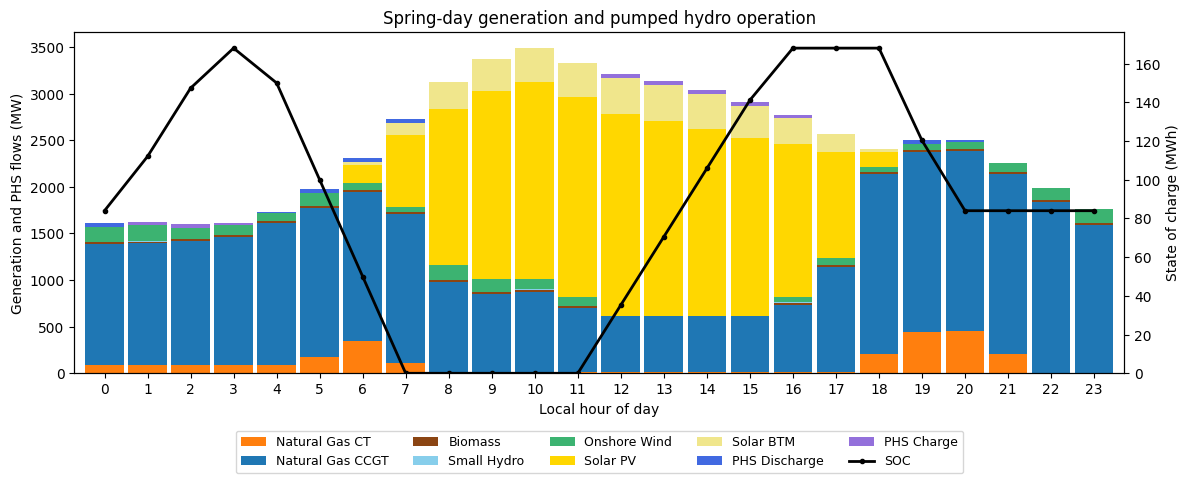

In [16]:
# Generation sources and PHS flows;

# THIS BAR CHART HAS BEEN IMPROVED WITH CHATGPT, notably for the aesthetic
# The resources have been selected by hand.

resources = ["Natural Gas CT", "Natural Gas CCGT", "Biomass",
             "Small Hydro", "Onshore Wind", "Solar PV", "Solar BTM",
             "PHS Discharge", "PHS Charge"]
colors = ["tab:orange", "tab:blue", "saddlebrown", "skyblue",
          "mediumseagreen",
          "gold", "khaki", "royalblue", "mediumpurple"]

ax = gen_by_type[resources].plot.bar(stacked=True, width=0.9,
                                   color=colors, figsize=(12, 5))
ax.set_xlabel("Local hour of day")
ax.set_xticklabels(T_period % 24, rotation=0)
ax.set_ylabel("Generation and PHS flows (MW)")
ax.set_title("Spring-day generation and pumped hydro operation")

ax_soc = ax.twinx()
ax_soc.plot(np.arange(len(T_period)), gen_by_type["SOC"],
            color="black", linewidth=2, marker="o", markersize=3, label="SOC")
ax_soc.set_ylabel("State of charge (MWh)")
ax_soc.set_ylim(0, 1.05 * energy_cap)

handles, labels = ax.get_legend_handles_labels()
soc_handles, soc_labels = ax_soc.get_legend_handles_labels()
ax.legend(handles + soc_handles, labels + soc_labels,
          loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5, fontsize=9)
plt.tight_layout()
plt.show()

$\color{red}{\text{Run the code below (same as from class) to see the number of thermal commitments each time step.}}$

<Axes: xlabel='Hour'>

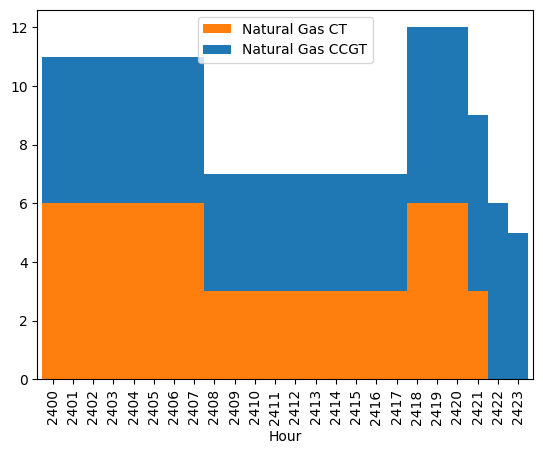

In [17]:
commit_by_type = pd.DataFrame({"Natural Gas CT": commit[CT].sum(axis=1), "Natural Gas CCGT": commit[CCGT].sum(axis=1)})
commit_by_type.plot.bar(stacked=True, width=1, color=["tab:orange","tab:blue"])

$\color{red}{\text{Compare your results to those from class (the case with StartupCosts > 0). Have any thermal commitments changed?}}$

 Something has indeed changed. In the comparison run, CCGT commitments remain unchanged, while CT commitments change. For example, during 08:00–17:00, the CT count increases from 3 to 4. Unlike the class model’s free PHS generation, the storage model requires charging and limits discharge by stored energy.



$\color{red}{\text{Interpret what is happening with the PHS facility during the day in terms of charging and discharging.}}$

PHS charges overnight around 01:00–02:00 and around midday, 12:00–16:00, to supply the morning and evening demand peaks. SOC reaches its maximum of after midday charging. Small late-evening charging restores the final SOC to its initial value.

$\color{red}{\text{Has curtailment reduced? Explain this in the context of the PHS operation.}}$

Curtailment has indeed reduced. Comparing the same non-PHS generators, curtailment decreases. Pumping absorbs otherwise unused generation during the solar-rich period.